In [2]:
import networkx as nx
import matplotlib.pyplot as plt 

In [2]:
G = nx.Graph()

G.add_node(1)
G.add_node(2)
G.add_edge(1,2)
G.add_nodes_from([3,4,5])
G.add_edges_from([(1,4),(3,4),(2,4),(3,2),(3,5)])

print(G)
print(G.nodes)
print(G.edges)

Graph with 5 nodes and 6 edges
[1, 2, 3, 4, 5]
[(1, 2), (1, 4), (2, 4), (2, 3), (3, 4), (3, 5)]


In [3]:
G.remove_node(5)

print(G)
print(G.nodes)
print(G.edges)


Graph with 4 nodes and 5 edges
[1, 2, 3, 4]
[(1, 2), (1, 4), (2, 4), (2, 3), (3, 4)]


LISTA DE ADYACENCIA

In [4]:
print(G[1])
print(G[1][2]), print(G.adj[1][2])
print("El diccionario de cada vértice vecino es de la forma {atributo:dato} que contiene informacion\n" \
"que puedes almacenar sobre cada vertice")

{2: {}, 4: {}}
{}
{}
El diccionario de cada vértice vecino es de la forma {atributo:dato} que contiene informacion
que puedes almacenar sobre cada vertice


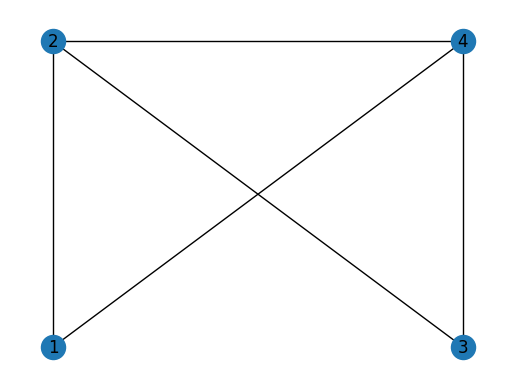

In [5]:
plot = plt.plot()

nx.draw(G, with_labels=True, pos={1:(0,0), 2:(0,1), 3:(1,0), 4:(1,1)})
plt.show()

In [6]:
G2 = nx.Graph()
G2.add_nodes_from((["a", "b", 11, 10, 3.14]))
G2.add_edge("a",10, object="Una cadena", weight=1.1)
G2.add_edges_from([("a",3.14,{"object":"Otra cadena", "weight":1.2}), ("b",11,{"object":"Un objeto", "weight":5.7})])

print(G2.nodes)
print(G2.edges)
print(G2["a"])

['a', 'b', 11, 10, 3.14]
[('a', 10), ('a', 3.14), ('b', 11)]
{10: {'object': 'Una cadena', 'weight': 1.1}, 3.14: {'object': 'Otra cadena', 'weight': 1.2}}


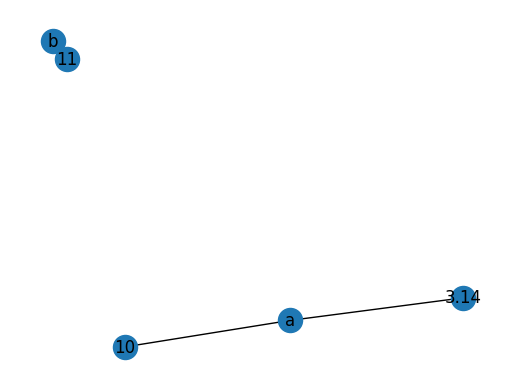

In [7]:
plot = plt.plot()

nx.draw(G2, with_labels=True)
plt.show()

GRAFOS DIRIGIDOS

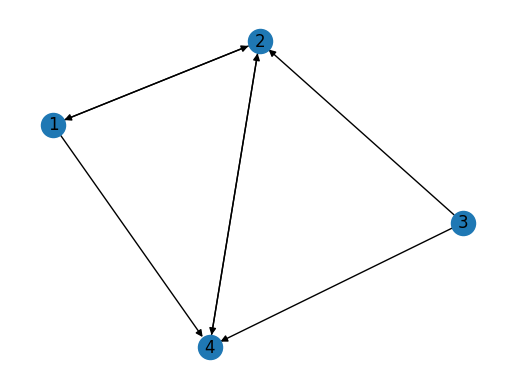

In [8]:
Gd = nx.DiGraph()
Gd.add_nodes_from([1,2,3,4])
Gd.add_edges_from([(1,2),(2,1),(1,4),(3,4),(2,4),(4,2),(3,2)])

plot = plt.plot()

nx.draw(Gd, with_labels=True)
plt.show()


In [9]:
print(G.degree)
print(Gd.in_degree)
print(Gd.out_degree)

[(1, 2), (2, 3), (3, 2), (4, 3)]
[(1, 1), (2, 3), (3, 0), (4, 3)]
[(1, 2), (2, 2), (3, 2), (4, 1)]


In [10]:
componentes = nx.connected_components(G2)
print(list(componentes))


[{'a', 10, 3.14}, {'b', 11}]


In [11]:
componentes_conexas = nx.weakly_connected_components(Gd)
print(list(componentes_conexas))

componentes_fuertemente_conexas = nx.strongly_connected_components(Gd)
print(list(componentes_fuertemente_conexas))

[{1, 2, 3, 4}]
[{1, 2, 4}, {3}]


[1, 4, 3]


{(1, 4): Text(0.1743495501049982, 0.5271780830767578, '1'),
 (4, 3): Text(0.29113776993727647, -0.472813154083902, '2')}

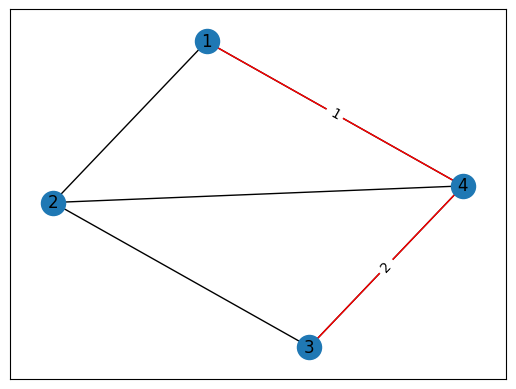

In [12]:
camino = nx.shortest_path(G,1,3)
print(camino)
pos = nx.spring_layout(G)
nx.draw_networkx(G, with_labels=True, pos=pos)
nx.draw_networkx_edges(G, pos=pos, arrows=True, edgelist=[(1,4),(4,3)], edge_color="r")
nx.draw_networkx_edge_labels(G, pos=pos, edge_labels={(1,4):'1', (4,3):'2'})

In [19]:
import osmnx as ox

def procesa_grafo(multidigrafo:nx.MultiDiGraph) -> nx.DiGraph:
    """ Función que recupera el quiver de calles de Madrid de OpenStreetMap.
    Args:
        multidigrafo: multidigrafo de las calles de Madrid obtenido de OpenStreetMap.
    Returns:
        nx.DiGraph: Grafo dirigido y sin bucles asociado al multidigrafo dado.
    Raises: None
    """

    G = ox.convert.to_digraph(multidigrafo) #quita aristas repetidas pero no bucles 

    loops = list(nx.selfloop_edges(G)) #bucles
    G.remove_edges_from(loops)

    return G

MD = nx.MultiDiGraph()
MD.add_nodes_from([1,2,3,4])
MD.add_edges_from([
    (1,2,{"length": 1}),
    (1,3,{"length": 1}),
    (3,1,{"length": 1}),
    (4,2,{"length": 1}),
    (1,1,{"length": 1}),
    (1,2,{"length": 2}),  # segunda arista paralela con otra longitud
])

print(MD.nodes, MD.edges)
G = procesa_grafo(MD)
print(G.nodes, G.edges)

[1, 2, 3, 4] [(1, 2, 0), (1, 2, 1), (1, 3, 0), (1, 1, 0), (3, 1, 0), (4, 2, 0)]
[1, 2, 3, 4] [(1, 2), (1, 3), (3, 1), (4, 2)]


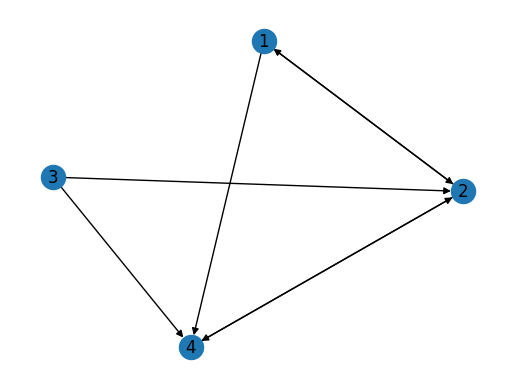

In [ ]:
import grafo_pesado as gp
Gd = nx.DiGraph()
Gd.add_nodes_from([1,2,3,4])
Gd.add_edges_from([(1,2),(2,1),(1,4),(3,4),(2,4),(4,2),(3,2)])

plot = plt.plot()

nx.draw(Gd, with_labels=True)
plt.show()

camino = gp.camino_minimo(Gd, )